# I-N20 — ISLES2022 nnU-Net Residual Encoder

- 입력: DWI + ADC
- 단일 변경: PlainConv encoder → ResidualEncoderUNet
- 300 epochs, early stopping 없음
- epoch 150부터 10 epoch 간격 full-volume validation
- macro Dice Top-3의 ±5 epoch 재평가
- 최종 선택: Dice 0.01 이내에서 lesion recall 우선
- 결과: `runs/I-nnunet`


In [10]:
from pathlib import Path
import json, os, subprocess, time
import pandas as pd

ROOT = Path("/home/stu03/workspace/model")
CONFIG = ROOT / "configs/experiments/ischemia/I-N20.yaml"
DATA_ROOT = Path("/home/stu03/workspace/datasets/ischemic/nnunet")
RESULTS_ROOT = ROOT / "runs/I-nnunet"
PYTHON = ROOT / ".venv/bin/python"
LAUNCHER = ROOT / "scripts/ischemia/training/run_i_n20.py"
MODEL_NAME = "nnUNetTrainerIschemiaResidualEncoder__IschemiaPlansResidualEncoderV1__3d_fullres"
FOLD = RESULTS_ROOT / "Dataset502_ISLES2022" / MODEL_NAME / "fold_0"
PROGRESS = FOLD / "progress.json"
HISTORY = FOLD / "full_validation_history.json"
PID_FILE = ROOT / "runs/I-nnunet/I-N20/train.pid"
LOG_FILE = ROOT / "runs/I-nnunet/I-N20/train.log"

for name, path in {"config": CONFIG, "data": DATA_ROOT, "python": PYTHON, "launcher": LAUNCHER}.items():
    print(f"{name:10s} {path.exists()}  {path}")


config     True  /home/stu03/workspace/model/configs/experiments/ischemia/I-N20.yaml
data       True  /home/stu03/workspace/datasets/ischemic/nnunet
python     True  /home/stu03/workspace/model/.venv/bin/python
launcher   True  /home/stu03/workspace/model/scripts/ischemia/training/run_i_n20.py


## 1. Dry-run 및 Residual Encoder plans 확인


In [11]:
base = [str(PYTHON), str(LAUNCHER), "--config", str(CONFIG)]
subprocess.run(base + ["--dry-run"], cwd=ROOT, check=True)
prepare = ROOT / "scripts/ischemia/preprocessing/prepare_i_n20_plans.py"
subprocess.run([str(PYTHON), str(prepare), "--config", str(CONFIG), "--data-root", str(DATA_ROOT)], cwd=ROOT, check=True)
plans_path = DATA_ROOT / "nnUNet_preprocessed/Dataset502_ISLES2022/IschemiaPlansResidualEncoderV1.json"
plans = json.loads(plans_path.read_text())
arch = plans["configurations"]["3d_fullres"]["architecture"]
assert arch["network_class_name"].endswith("ResidualEncoderUNet")
assert arch["arch_kwargs"]["n_blocks_per_stage"] == [1, 3, 4, 6, 6]
print("Residual Encoder plans: PASS")
print(json.dumps(arch, indent=2))


{
  "experiment": "I-N20",
  "mode": "new",
  "output_folder": "/home/stu03/workspace/model/runs/I-nnunet/Dataset502_ISLES2022/nnUNetTrainerIschemiaResidualEncoder__IschemiaPlansResidualEncoderV1__3d_fullres/fold_0",
  "prepare": [
    "/home/stu03/workspace/model/.venv/bin/python",
    "/home/stu03/workspace/model/scripts/ischemia/preprocessing/prepare_i_n20_plans.py",
    "--config",
    "/home/stu03/workspace/model/configs/experiments/ischemia/I-N20.yaml",
    "--data-root",
    "/home/stu03/workspace/datasets/ischemic/nnunet"
  ],
  "train": [
    "/home/stu03/workspace/model/.venv/bin/nnUNetv2_train",
    "502",
    "3d_fullres",
    "0",
    "-tr",
    "nnUNetTrainerIschemiaResidualEncoder",
    "-p",
    "IschemiaPlansResidualEncoderV1",
    "-device",
    "cuda"
  ],
  "post_training_selection": [
    "/home/stu03/workspace/model/.venv/bin/python",
    "/home/stu03/workspace/model/scripts/ischemia/validation/evaluate_i_n20_neighborhood.py",
    "--config",
    "/home/stu03/work

## 2. GPU 확인 및 학습 시작/재개

이미 PID가 실행 중이면 중복으로 시작하지 않습니다.


In [12]:
subprocess.run(["nvidia-smi"], check=False)
PID_FILE.parent.mkdir(parents=True, exist_ok=True)
LOG_FILE.parent.mkdir(parents=True, exist_ok=True)

def pid_running():
    if not PID_FILE.is_file():
        return False
    try:
        pid = int(PID_FILE.read_text().strip())
        return subprocess.run(["kill", "-0", str(pid)], capture_output=True).returncode == 0
    except (ValueError, OSError):
        return False

if pid_running():
    print("이미 실행 중 PID:", PID_FILE.read_text().strip())
else:
    log = LOG_FILE.open("a", encoding="utf-8")
    process = subprocess.Popen(base, cwd=ROOT, stdout=log, stderr=subprocess.STDOUT, start_new_session=True)
    PID_FILE.write_text(str(process.pid), encoding="utf-8")
    print("I-N20 시작 PID:", process.pid)
    print("로그:", LOG_FILE)


Mon Sep 14 12:22:35 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 595.84                 Driver Version: 595.84         CUDA Version: 13.2     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 5090        Off |   00000000:01:00.0 Off |                  N/A |
|  0%   37C    P8             13W /  575W |    5355MiB /  32607MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 3. 실시간 진행률

셀 중지는 모니터만 멈추며 학습 프로세스는 계속 실행됩니다.


In [13]:
from IPython.display import clear_output, display

def read_json(path, default=None):
    try:
        return json.loads(path.read_text(encoding="utf-8"))
    except (FileNotFoundError, json.JSONDecodeError):
        return {} if default is None else default

def fmt(seconds):
    if seconds is None:
        return "-"
    seconds = int(seconds)
    return f"{seconds//3600:02d}:{seconds%3600//60:02d}:{seconds%60:02d}"

while True:
    clear_output(wait=True)
    p = read_json(PROGRESS)
    history = read_json(HISTORY, [])
    running = pid_running()
    ranked = sorted(history, key=lambda x: x.get("macro_dice_positive", -1), reverse=True)[:3]
    row = {
        "실험": "I-N20", "상태": p.get("status", "starting" if running else "not_started"),
        "Epoch": f'{p.get("current_epoch", 0)}/{p.get("total_epochs", 300)}',
        "진행률(%)": p.get("progress_percent", 0), "ETA": fmt(p.get("eta_seconds")),
        "Online Dice": p.get("pseudo_dice"), "Online Recall": p.get("pseudo_recall"),
        "Composite": p.get("composite"), "Full Macro Dice": p.get("full_macro_dice"),
        "Best Full Dice": p.get("best_full_macro_dice"),
        "Top-3": [(x.get("epoch"), round(x.get("macro_dice_positive", 0), 4)) for x in ranked],
        "보존 CKPT": p.get("retained_epoch_checkpoints"), "PID": PID_FILE.read_text().strip() if running else "-",
    }
    display(pd.DataFrame([row]))
    if LOG_FILE.is_file():
        print("\n로그 마지막 15줄:\n", "".join(LOG_FILE.read_text(errors="replace").splitlines(True)[-15:]))
    status = p.get("status")
    if status in {"completed", "early_stopped", "failed"}:
        print("학습 프로세스 종료:", status)
        break
    if not running and p:
        print("PID가 종료되었습니다. 로그의 traceback을 확인하세요.")
        break
    time.sleep(10)


,실험,상태,Epoch,진행률(%),ETA,Online Dice,Online Recall,Composite,Full Macro Dice,Best Full Dice,Top-3,보존 CKPT,PID
0,I-N20,failed,0/300,0.0,-,None,None,None,None,None,"[(220, 0.8116), (183, 0.8074), (177, 0.8074)]",37,2014030



로그 마지막 15줄:
 #######################################################################

Traceback (most recent call last):
  File "/home/stu03/workspace/model/.venv/bin/nnUNetv2_train", line 8, in <module>
    sys.exit(run_training_entry())
             ^^^^^^^^^^^^^^^^^^^^
  File "/home/stu03/workspace/model/.venv/lib/python3.12/site-packages/nnunetv2/run/run_training.py", line 259, in run_training_entry
    run_training(args.dataset_name_or_id, args.configuration, args.fold, args.tr, args.p, args.pretrained_weights,
  File "/home/stu03/workspace/model/.venv/lib/python3.12/site-packages/nnunetv2/run/run_training.py", line 200, in run_training
    nnunet_trainer.run_training()
  File "/home/stu03/workspace/model/src/brainon_ai/nnunet/trainers/configurable_trainer.py", line 664, in run_training
    self.on_train_start()
  File "/home/stu03/workspace/model/src/brainon_ai/nnunet/trainers/configurable_trainer.py", line 184, in on_train_start
    raise RuntimeError(
RuntimeError: 같은 nnU-Net 

## 4. 최종 선택 및 평가 결과 확인


In [14]:
selection = read_json(FOLD / "final_selection.json")
if not selection:
    print("아직 final_selection.json이 없습니다.")
else:
    selected = selection["selected"]
    display(pd.DataFrame([{
        "epoch": selected["epoch"],
        "macro_dice": selected["macro_dice_positive"],
        "lesion_detection_rate": selected["lesion_detection_rate"],
        "detected/total": f'{selected["detected_lesions"]}/{selected["total_lesions"]}',
        "mean_lesion_dice": selected["mean_lesion_dice"],
    }]))
    print("checkpoint:", FOLD / "checkpoint_best_dual_criteria.pth")
    print("상세 지표 계약:", json.loads(CONFIG.read_text()) if False else "I-N20.yaml evaluation.report 참조")


,epoch,macro_dice,lesion_detection_rate,detected/total,mean_lesion_dice
0,183,0.807369,0.657371,165/251,0.457096


checkpoint: /home/stu03/workspace/model/runs/I-nnunet/Dataset502_ISLES2022/nnUNetTrainerIschemiaResidualEncoder__IschemiaPlansResidualEncoderV1__3d_fullres/fold_0/checkpoint_best_dual_criteria.pth
상세 지표 계약: I-N20.yaml evaluation.report 참조


## 5. 병변 크기별 Dice 및 탐지율

최종 선택 checkpoint의 GT connected component를 `<1`, `1–5`, `5–20`, `≥20mL`로 구분합니다. 미검출 병변의 Dice는 0으로 포함됩니다.


,size_group,gt_lesions,detected_lesions,detected/total,detection_rate,mean_lesion_dice,median_lesion_dice,median_volume_ml
0,<0.01 mL,18,2,2/18,0.111111,0.092593,0.000000,0.007151
1,0.01–0.05 mL,76,28,28/76,0.368421,0.253533,0.000000,0.030996
2,0.05–0.1 mL,30,18,18/30,0.600000,0.388807,0.311111,0.066661
3,0.1–0.5 mL,72,65,65/72,0.902778,0.592011,0.681159,0.200737
4,≥0.5 mL,55,52,52/55,0.945455,0.718309,0.832487,2.568000


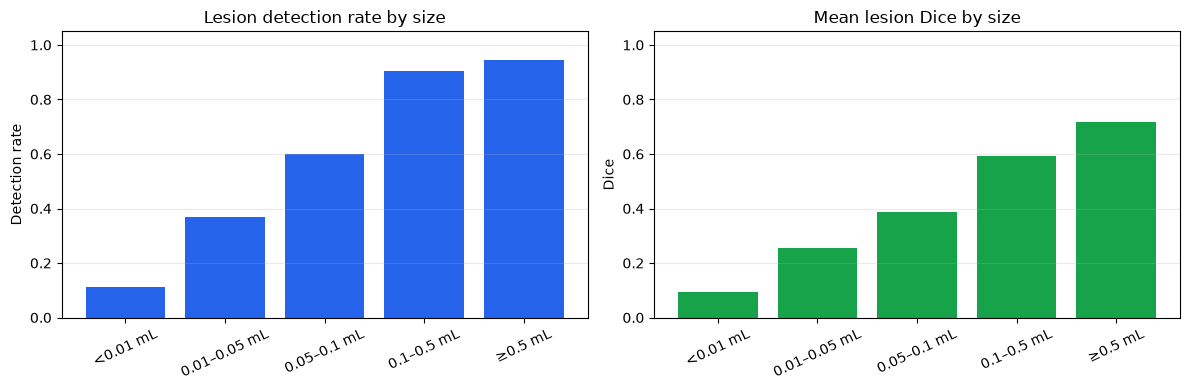

In [15]:
if not selection:
    print("최종 선택이 완료되지 않았습니다.")
else:
    size_path = Path(selection["selected"]["size_summary_csv"])
    size_df = pd.read_csv(size_path)
    display(size_df[[
        "size_group", "gt_lesions", "detected_lesions", "detected/total",
        "detection_rate", "mean_lesion_dice", "median_lesion_dice", "median_volume_ml",
    ]])

    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].bar(size_df["size_group"].astype(str), size_df["detection_rate"], color="#2563eb")
    axes[0].set(title="Lesion detection rate by size", ylabel="Detection rate", ylim=(0, 1.05))
    axes[1].bar(size_df["size_group"].astype(str), size_df["mean_lesion_dice"], color="#16a34a")
    axes[1].set(title="Mean lesion Dice by size", ylabel="Dice", ylim=(0, 1.05))
    for ax in axes:
        ax.tick_params(axis="x", rotation=25)
        ax.grid(axis="y", alpha=0.25)
    plt.tight_layout(); plt.show()


## 6. 최종 핵심 지표

Voxel overlap, 병변 검출, 경계 거리 및 병변 부피 오차를 함께 확인합니다.


In [17]:
metrics_summary = read_json(FOLD / "final_metrics/summary.json")
if not metrics_summary:
    print("final_metrics/summary.json이 아직 없습니다.")
else:
    macro = metrics_summary["macro"]
    keys = [
        ("dice", "Macro Dice"), ("iou", "Macro IoU"),
        ("recall_sensitivity", "Voxel Recall"), ("precision", "Voxel Precision"),
        ("hd95_mm", "HD95 (mm)"), ("assd_mm", "ASSD (mm)"),
        ("nsd_2mm", "NSD @ 2mm"), ("abs_volume_error_ml", "AVD (mL)"),
        ("relative_volume_error_pct", "RVD (%)"),
    ]
    overview = {label: macro[key]["mean"] for key, label in keys}
    overview.update({
        "Lesion Recall": metrics_summary["micro_lesion_recall"],
        "Lesion Precision": metrics_summary["micro_lesion_precision"],
        "FP/scan": metrics_summary["fp_per_scan"],
        "Complete miss cases": metrics_summary["complete_miss_cases"],
    })
    display(pd.DataFrame([overview]).T.rename(columns={0: "value"}))


,value
Macro Dice,0.812438
Macro IoU,0.703346
Voxel Recall,0.774290
Voxel Precision,0.903439
HD95 (mm),6.320579
ASSD (mm),1.313590
NSD @ 2mm,0.920651
AVD (mL),2.409900
RVD (%),-12.827890
Lesion Recall,0.657371


## 7. 실패 사례 및 부피 일치도

낮은 Dice, 완전 미검출, 큰 부피 오차 사례를 우선 검토합니다.


,case_id,dice,recall_sensitivity,precision,lesion_recall,false_positive_lesions,hd95_mm,nsd_2mm,gt_volume_ml,pred_volume_ml,abs_volume_error_ml
10,sub-strokecase0068,0.279412,0.164859,0.915663,0.666667,1,38.178047,0.395753,3.688,0.664,3.024
18,sub-strokecase0098,0.415929,0.271676,0.886792,0.533333,1,28.284271,0.672566,1.384,0.424,0.960
11,sub-strokecase0076,0.529851,0.375165,0.901587,0.642857,9,24.738634,0.758201,6.056,2.520,3.536
8,sub-strokecase0050,0.686215,0.528831,0.976967,0.636364,2,6.324555,0.794601,15.400,8.336,7.064
36,sub-strokecase0234,0.695652,0.551724,0.941176,1.000000,0,2.497056,0.956522,0.232,0.136,0.096
6,sub-strokecase0040,0.717586,0.573474,0.958438,0.666667,1,6.000000,0.858342,10.616,6.352,4.264
20,sub-strokecase0138,0.717949,0.560000,1.000000,1.000000,0,2.000000,1.000000,0.200,0.112,0.088
2,sub-strokecase0018,0.733333,0.578947,1.000000,1.000000,0,3.464102,0.909091,1.064,0.616,0.448
15,sub-strokecase0092,0.766834,0.721590,0.818132,0.750000,4,6.324555,0.771408,66.032,58.240,7.792
19,sub-strokecase0118,0.795652,0.687970,0.943299,0.833333,2,4.000000,0.917940,6.384,4.656,1.728


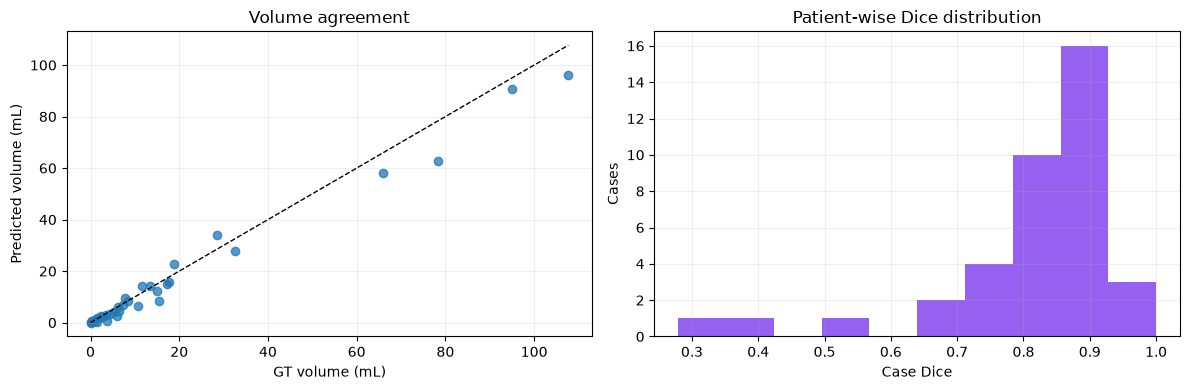

In [18]:
per_case_path = FOLD / "final_metrics/per_case.csv"
if not per_case_path.is_file():
    print("final_metrics/per_case.csv가 아직 없습니다.")
else:
    case_df = pd.read_csv(per_case_path)
    worst = case_df.sort_values(
        ["dice", "lesion_recall", "abs_volume_error_ml"],
        ascending=[True, True, False],
    ).head(10)
    display(worst[[
        "case_id", "dice", "recall_sensitivity", "precision",
        "lesion_recall", "false_positive_lesions", "hd95_mm",
        "nsd_2mm", "gt_volume_ml", "pred_volume_ml", "abs_volume_error_ml",
    ]])

    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].scatter(case_df["gt_volume_ml"], case_df["pred_volume_ml"], alpha=0.75)
    limit = max(case_df["gt_volume_ml"].max(), case_df["pred_volume_ml"].max())
    axes[0].plot([0, limit], [0, limit], "k--", linewidth=1)
    axes[0].set(xlabel="GT volume (mL)", ylabel="Predicted volume (mL)", title="Volume agreement")
    axes[1].hist(case_df["dice"], bins=10, color="#7c3aed", alpha=0.8)
    axes[1].set(xlabel="Case Dice", ylabel="Cases", title="Patient-wise Dice distribution")
    for ax in axes: ax.grid(alpha=0.2)
    plt.tight_layout(); plt.show()
